In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Day 11 libraries imported successfully.")

Day 11 libraries imported successfully.


In [3]:
day11_input_path = Path(
    "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"
)

if not day11_input_path.exists():
    raise FileNotFoundError(
        f"Input dataset not found: {day11_input_path.resolve()}"
    )

df_day11_source = pd.read_csv(
    day11_input_path,
    encoding="cp1252",
    low_memory=False
)

df_day11 = df_day11_source.copy()

print("Day 11 source dataset loaded successfully.")
print("Dataset shape:", df_day11.shape)

display(df_day11.head())

Day 11 source dataset loaded successfully.
Dataset shape: (180519, 56)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode,Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Revenue_Per_Unit,Profit_Margin,Discount_Level,Region_Market,Shipping_Mode_Rank,Is_Corporate_Customer,Order_Quantity_Category,Operational_Risk_Profile,Delivery_Status,Risk_Status
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,78521.0,3,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class,2,1,0,0,Major Delay,0.666667,99.99,0.319412,Low Discount,Pacific Asia - South Asia,4,0,Large,High Risk - Slower Shipping,Delayed,High Risk
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class,0,0,1,0,On Time / Early,1.000000,39.99,0.243611,Medium Discount,LATAM - Central America,4,0,Large,Lower Risk,On Time,Low Risk
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class,0,0,1,0,On Time / Early,1.000000,199.99,0.436822,Low Discount,LATAM - Central America,4,0,Small,Lower Risk,On Time,Low Risk
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class,2,1,0,0,Major Delay,0.666667,199.99,-0.209460,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class,2,1,0,0,Major Delay,0.666667,50.00,0.200000,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk


## Dataset Overview & Validation

In [4]:
print("Total rows:", len(df_day11))
print("Total columns:", len(df_day11.columns))

print(
    "Duplicate rows:",
    df_day11.duplicated().sum()
)

required_columns = [
    "Customer Segment",
    "Order Customer Id",
    "Customer Id",
    "Is_Delayed",
    "Late_delivery_risk",
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Order Item Quantity",
    "Shipping_Delay_Days",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Delivery Status",
    "Market",
    "Order Country"
]

missing_columns = [
    col for col in required_columns
    if col not in df_day11.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are available.")    

Total rows: 180519
Total columns: 56
Duplicate rows: 0
All required columns are available.


### Checking missing values

In [5]:
customer_analysis_columns = [
    "Customer Segment",
    "Order Customer Id",
    "Is_Delayed",
    "Late_delivery_risk",
    "Sales",
    "Order Profit Per Order",
    "Order Item Total",
    "Order Item Quantity",
    "Shipping_Delay_Days",
    "Delivery Status",
    "Market",
    "Order Country"
]

customer_missing_summary = (
    df_day11[customer_analysis_columns]
    .isna()
    .sum()
    .to_frame(name="Missing_Values")
    .sort_values(
        "Missing_Values",
        ascending=False
    )
)

display(customer_missing_summary)

,Missing_Values
Customer Segment,0
Order Customer Id,0
Is_Delayed,0
Late_delivery_risk,0
Sales,0
Order Profit Per Order,0
Order Item Total,0
Order Item Quantity,0
Shipping_Delay_Days,0
Delivery Status,0


## Customer Segment Inspection

In [6]:
customer_segment_counts = (
    df_day11["Customer Segment"]
    .value_counts(dropna=False)
    .rename_axis("Customer Segment")
    .reset_index(name="Shipment_Count")
)

display(customer_segment_counts)

,Customer Segment,Shipment_Count
0,Consumer,93504
1,Corporate,54789
2,Home Office,32226


In [7]:
total_records = len(df_day11)

customer_segment_counts["Shipment_Share_%"] = (
    customer_segment_counts["Shipment_Count"]
    / total_records
    * 100
)

customer_segment_counts["Shipment_Share_%"] = (
    customer_segment_counts["Shipment_Share_%"]
    .round(2)
)

display(customer_segment_counts)

,Customer Segment,Shipment_Count,Shipment_Share_%
0,Consumer,93504,51.80
1,Corporate,54789,30.35
2,Home Office,32226,17.85


## Customer Segment Shipment Analysis

In [8]:
customer_segment_shipment_analysis = (
    df_day11
    .groupby(
        "Customer Segment",
        dropna=False
    )
    .agg(
        Total_Shipments=(
            "Customer Segment",
            "size"
        ),
        Unique_Customers=(
            "Order Customer Id",
            "nunique"
        ),
        Delayed_Shipments=(
            "Is_Delayed",
            lambda s: s.eq(1).sum()
        ),
        On_Time_Shipments=(
            "Is_Delayed",
            lambda s: s.eq(0).sum()
        )
    )
    .reset_index()
)

customer_segment_shipment_analysis[
    "Shipment_Share_%"
] = (
    customer_segment_shipment_analysis["Total_Shipments"]
    / len(df_day11)
    * 100
)

customer_segment_shipment_analysis[
    "Actual_Delay_Rate_%"
] = (
    customer_segment_shipment_analysis["Delayed_Shipments"]
    / customer_segment_shipment_analysis["Total_Shipments"]
    * 100
)

customer_segment_shipment_analysis[
    "On_Time_Rate_%"
] = (
    customer_segment_shipment_analysis["On_Time_Shipments"]
    / customer_segment_shipment_analysis["Total_Shipments"]
    * 100
)

rate_columns = [
    "Shipment_Share_%",
    "Actual_Delay_Rate_%",
    "On_Time_Rate_%"
]

customer_segment_shipment_analysis[rate_columns] = (
    customer_segment_shipment_analysis[rate_columns]
    .round(2)
)

customer_segment_shipment_analysis = (
    customer_segment_shipment_analysis
    .sort_values(
        "Total_Shipments",
        ascending=False
    )
    .reset_index(drop=True)
)

display(customer_segment_shipment_analysis)

,Customer Segment,Total_Shipments,Unique_Customers,Delayed_Shipments,On_Time_Shipments,Shipment_Share_%,Actual_Delay_Rate_%,On_Time_Rate_%
0,Consumer,93504,10695,53573,39931,51.80,57.29,42.71
1,Corporate,54789,6239,31291,23498,30.35,57.11,42.89
2,Home Office,32226,3718,18536,13690,17.85,57.52,42.48


## Customer Segment Sales & Profitibility

In [9]:
customer_segment_financial_analysis = (
    df_day11
    .groupby(
        "Customer Segment",
        dropna=False
    )
    .agg(
        Total_Shipments=(
            "Customer Segment",
            "size"
        ),
        Total_Sales=(
            "Sales",
            "sum"
        ),
        Average_Sales_Per_Record=(
            "Sales",
            "mean"
        ),
        Total_Order_Profit=(
            "Order Profit Per Order",
            "sum"
        ),
        Average_Order_Profit=(
            "Order Profit Per Order",
            "mean"
        ),
        Total_Order_Item_Value=(
            "Order Item Total",
            "sum"
        ),
        Average_Order_Item_Value=(
            "Order Item Total",
            "mean"
        )
    )
    .reset_index()
)

customer_segment_financial_analysis[
    "Sales_Share_%"
] = (
    customer_segment_financial_analysis["Total_Sales"]
    / df_day11["Sales"].sum()
    * 100
)

customer_segment_financial_analysis[
    "Total_Sales"
] = (
    customer_segment_financial_analysis["Total_Sales"]
    .round(2)
)

customer_segment_financial_analysis[
    "Average_Sales_Per_Record"
] = (
    customer_segment_financial_analysis[
        "Average_Sales_Per_Record"
    ].round(2)
)

customer_segment_financial_analysis[
    "Total_Order_Profit"
] = (
    customer_segment_financial_analysis[
        "Total_Order_Profit"
    ].round(2)
)

customer_segment_financial_analysis[
    "Average_Order_Profit"
] = (
    customer_segment_financial_analysis[
        "Average_Order_Profit"
    ].round(2)
)

customer_segment_financial_analysis[
    "Total_Order_Item_Value"
] = (
    customer_segment_financial_analysis[
        "Total_Order_Item_Value"
    ].round(2)
)

customer_segment_financial_analysis[
    "Average_Order_Item_Value"
] = (
    customer_segment_financial_analysis[
        "Average_Order_Item_Value"
    ].round(2)
)

customer_segment_financial_analysis[
    "Sales_Share_%"
] = (
    customer_segment_financial_analysis[
        "Sales_Share_%"
    ].round(2)
)

display(
    customer_segment_financial_analysis
    .sort_values(
        "Total_Sales",
        ascending=False
    )
    .reset_index(drop=True)
)

,Customer Segment,Total_Shipments,Total_Sales,Average_Sales_Per_Record,Total_Order_Profit,Average_Order_Profit,Total_Order_Item_Value,Average_Order_Item_Value,Sales_Share_%
0,Consumer,93504,19095789.79,204.22,2073487.67,22.18,17164278.19,183.57,51.91
1,Corporate,54789,11168406.63,203.84,1202574.96,21.95,10030649.80,183.08,30.36
2,Home Office,32226,6520537.89,202.34,690840.34,21.44,5859474.05,181.82,17.73


## Customer Segment Delivery Delay Analysis

In [10]:
customer_segment_delay_analysis = (
    df_day11
    .groupby(
        "Customer Segment",
        dropna=False
    )
    .agg(
        Total_Shipments=(
            "Customer Segment",
            "size"
        ),
        Delayed_Shipments=(
            "Is_Delayed",
            lambda s: s.eq(1).sum()
        ),
        Average_Shipping_Delay_Days=(
            "Shipping_Delay_Days",
            "mean"
        ),
        Average_Actual_Shipping_Days=(
            "Days for shipping (real)",
            "mean"
        ),
        Average_Scheduled_Shipping_Days=(
            "Days for shipment (scheduled)",
            "mean"
        )
    )
    .reset_index()
)

customer_segment_delay_analysis[
    "Actual_Delay_Rate_%"
] = (
    customer_segment_delay_analysis["Delayed_Shipments"]
    / customer_segment_delay_analysis["Total_Shipments"]
    * 100
)

delay_numeric_columns = [
    "Actual_Delay_Rate_%",
    "Average_Shipping_Delay_Days",
    "Average_Actual_Shipping_Days",
    "Average_Scheduled_Shipping_Days"
]

customer_segment_delay_analysis[
    delay_numeric_columns
] = (
    customer_segment_delay_analysis[
        delay_numeric_columns
    ].round(2)
)

customer_segment_delay_analysis = (
    customer_segment_delay_analysis
    .sort_values(
        ["Actual_Delay_Rate_%", "Total_Shipments"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(customer_segment_delay_analysis)

,Customer Segment,Total_Shipments,Delayed_Shipments,Average_Shipping_Delay_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Actual_Delay_Rate_%
0,Home Office,32226,18536,0.58,3.51,2.93,57.52
1,Consumer,93504,53573,0.56,3.50,2.93,57.29
2,Corporate,54789,31291,0.56,3.49,2.93,57.11


## Customer Segment Risk Analysis

In [11]:
customer_segment_risk_analysis = (
    df_day11
    .groupby(
        "Customer Segment",
        dropna=False
    )
    .agg(
        Total_Shipments=(
            "Customer Segment",
            "size"
        ),
        High_Risk_Shipments=(
            "Late_delivery_risk",
            lambda s: s.eq(1).sum()
        ),
        Low_Risk_Shipments=(
            "Late_delivery_risk",
            lambda s: s.eq(0).sum()
        ),
        Actually_Delayed_Shipments=(
            "Is_Delayed",
            lambda s: s.eq(1).sum()
        )
    )
    .reset_index()
)

customer_segment_risk_analysis[
    "High_Risk_Share_%"
] = (
    customer_segment_risk_analysis["High_Risk_Shipments"]
    / customer_segment_risk_analysis["Total_Shipments"]
    * 100
)

customer_segment_risk_analysis[
    "Actual_Delay_Rate_%"
] = (
    customer_segment_risk_analysis[
        "Actually_Delayed_Shipments"
    ]
    / customer_segment_risk_analysis["Total_Shipments"]
    * 100
)

customer_segment_risk_analysis[
    ["High_Risk_Share_%", "Actual_Delay_Rate_%"]
] = (
    customer_segment_risk_analysis[
        ["High_Risk_Share_%", "Actual_Delay_Rate_%"]
    ].round(2)
)

display(
    customer_segment_risk_analysis
    .sort_values(
        "High_Risk_Share_%",
        ascending=False
    )
    .reset_index(drop=True)
)

,Customer Segment,Total_Shipments,High_Risk_Shipments,Low_Risk_Shipments,Actually_Delayed_Shipments,High_Risk_Share_%,Actual_Delay_Rate_%
0,Home Office,32226,17747,14479,18536,55.07,57.52
1,Consumer,93504,51248,42256,53573,54.81,57.29
2,Corporate,54789,29982,24807,31291,54.72,57.11


## Visualize Customer Segment Performance

### Shipment volume by customer segment

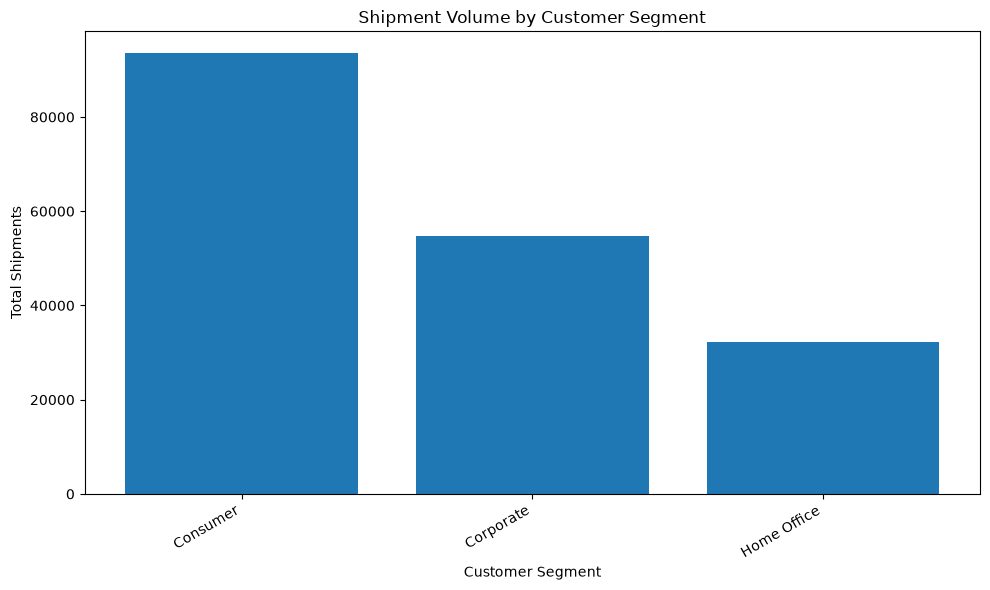

In [14]:
plot_data = (
    customer_segment_shipment_analysis
    .sort_values(
        "Total_Shipments",
        ascending=False
    )
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data["Customer Segment"].astype(str),
    plot_data["Total_Shipments"]
)

plt.title("Shipment Volume by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Shipments")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Actual delay rate by customer segment

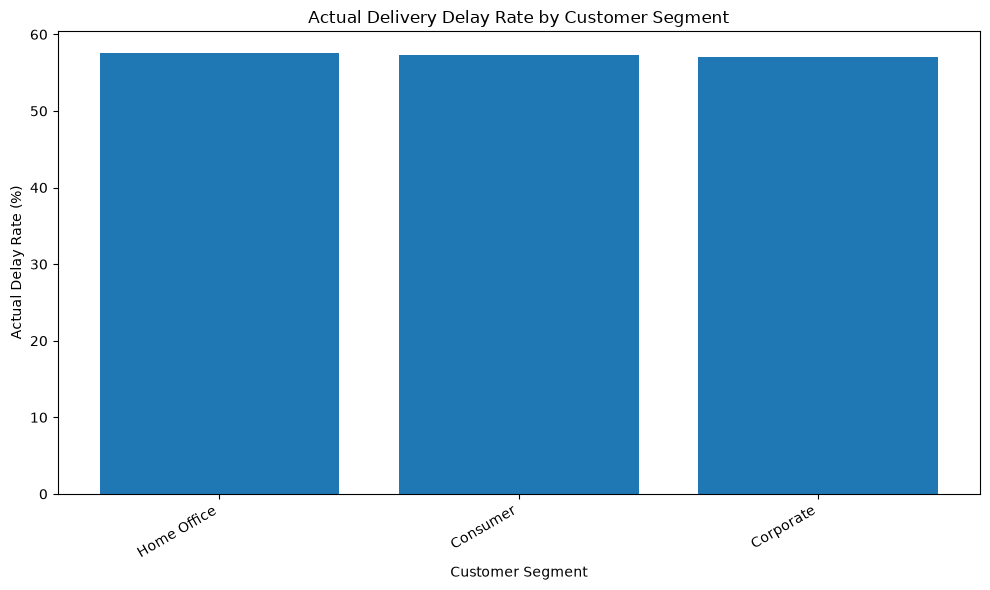

In [15]:
plot_data = (
    customer_segment_delay_analysis
    .sort_values(
        "Actual_Delay_Rate_%",
        ascending=False
    )
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data["Customer Segment"].astype(str),
    plot_data["Actual_Delay_Rate_%"]
)

plt.title("Actual Delivery Delay Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Actual Delay Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Total sales by customer segment

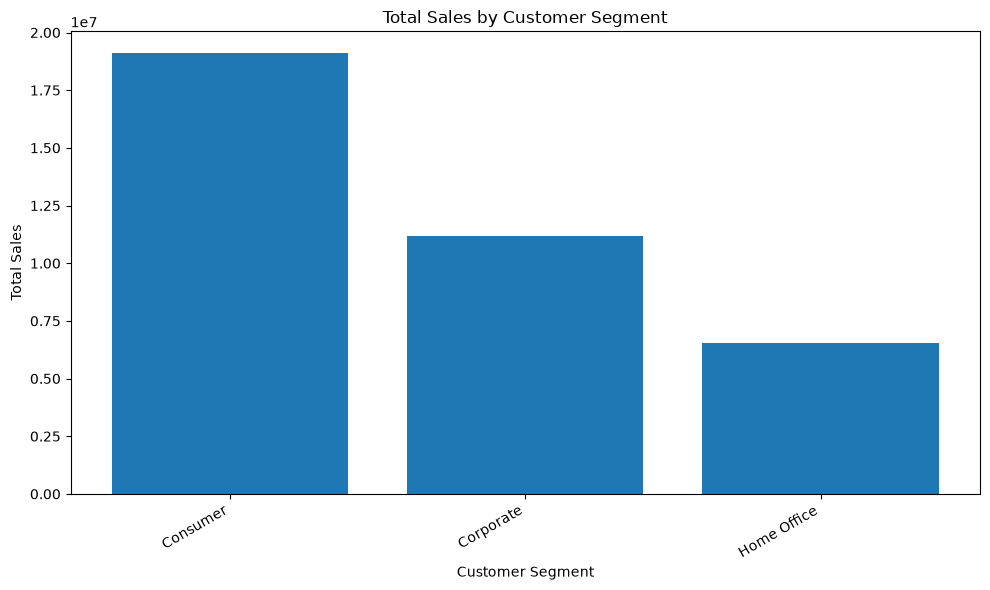

In [16]:
plot_data = (
    customer_segment_financial_analysis
    .sort_values(
        "Total_Sales",
        ascending=False
    )
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data["Customer Segment"].astype(str),
    plot_data["Total_Sales"]
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Total order profit by customer segment 

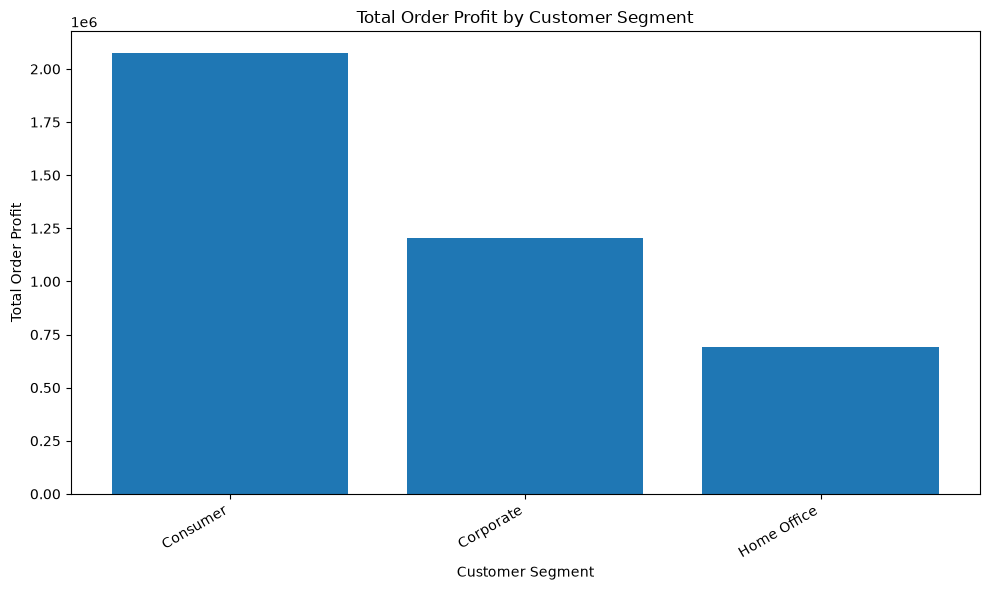

In [17]:
plot_data = (
    customer_segment_financial_analysis
    .sort_values(
        "Total_Order_Profit",
        ascending=False
    )
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data["Customer Segment"].astype(str),
    plot_data["Total_Order_Profit"]
)

plt.title("Total Order Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Order Profit")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Customer Segment KPI Summary 

In [19]:
valid_segment_data = (
    customer_segment_shipment_analysis
    .dropna(subset=["Customer Segment"])
)

if valid_segment_data.empty:
    highest_volume_segment = "Unavailable"
    lowest_volume_segment = "Unavailable"
else:
    highest_volume_segment = (
        valid_segment_data
        .sort_values(
            ["Total_Shipments", "Customer Segment"],
            ascending=[False, True]
        )
        .iloc[0]["Customer Segment"]
    )

    lowest_volume_segment = (
        valid_segment_data
        .sort_values(
            ["Total_Shipments", "Customer Segment"],
            ascending=[True, True]
        )
        .iloc[0]["Customer Segment"]
    )

valid_delay_data = (
    customer_segment_delay_analysis
    .dropna(subset=["Customer Segment", "Actual_Delay_Rate_%"])
)

if valid_delay_data.empty:
    highest_delay_segment = "Unavailable"
    lowest_delay_segment = "Unavailable"
else:
    highest_delay_segment = (
        valid_delay_data
        .sort_values(
            ["Actual_Delay_Rate_%", "Total_Shipments"],
            ascending=[False, False]
        )
        .iloc[0]["Customer Segment"]
    )

    lowest_delay_segment = (
        valid_delay_data
        .sort_values(
            ["Actual_Delay_Rate_%", "Total_Shipments"],
            ascending=[True, False]
        )
        .iloc[0]["Customer Segment"]
    )

valid_financial_data = (
    customer_segment_financial_analysis
    .dropna(subset=["Customer Segment", "Total_Sales"])
)

if valid_financial_data.empty:
    highest_sales_segment = "Unavailable"
else:
    highest_sales_segment = (
        valid_financial_data
        .sort_values(
            ["Total_Sales", "Customer Segment"],
            ascending=[False, True]
        )
        .iloc[0]["Customer Segment"]
    )

valid_profit_data = (
    customer_segment_financial_analysis
    .dropna(subset=["Customer Segment", "Total_Order_Profit"])
)

if valid_profit_data.empty:
    highest_profit_segment = "Unavailable"
else:
    highest_profit_segment = (
        valid_profit_data
        .sort_values(
            ["Total_Order_Profit", "Customer Segment"],
            ascending=[False, True]
        )
        .iloc[0]["Customer Segment"]
    )

day11_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipment Records",
        "Unique Customer IDs",
        "Unique Customer Segments",
        "Highest Shipment Volume Segment",
        "Lowest Shipment Volume Segment",
        "Highest Actual Delay Rate Segment",
        "Lowest Actual Delay Rate Segment",
        "Highest Sales Segment",
        "Highest Total Order Profit Segment",
        "Overall Actual Delay Rate (%)"
    ],

    "Value": [
        len(df_day11),
        df_day11["Order Customer Id"].nunique(),
        df_day11["Customer Segment"].nunique(dropna=True),
        highest_volume_segment,
        lowest_volume_segment,
        highest_delay_segment,
        lowest_delay_segment,
        highest_sales_segment,
        highest_profit_segment,
        round(
            df_day11["Is_Delayed"].eq(1).mean() * 100,
            2
        )
    ]
})

display(day11_kpis)

,Metric,Value
0,Total Shipment Records,180519
1,Unique Customer IDs,20652
2,Unique Customer Segments,3
3,Highest Shipment Volume Segment,Consumer
4,Lowest Shipment Volume Segment,Home Office
5,Highest Actual Delay Rate Segment,Home Office
6,Lowest Actual Delay Rate Segment,Corporate
7,Highest Sales Segment,Consumer
8,Highest Total Order Profit Segment,Consumer
9,Overall Actual Delay Rate (%),57.28


## Saving Day 11 Customer Segments Analysis Results 

In [21]:
day11_output_dir = Path("../data/analysis_data/")

if not day11_output_dir.exists():
    raise FileNotFoundError(
        f"Output directory does not exist: "
        f"{day11_output_dir.resolve()}"
    )

In [22]:
day11_outputs = {
    "APL_Day11_Customer_Segment_Distribution.csv":
        customer_segment_counts,

    "APL_Day11_Customer_Segment_Shipment_Analysis.csv":
        customer_segment_shipment_analysis,

    "APL_Day11_Customer_Segment_Financial_Analysis.csv":
        customer_segment_financial_analysis,

    "APL_Day11_Customer_Segment_Delay_Analysis.csv":
        customer_segment_delay_analysis,

    "APL_Day11_Customer_Segment_Risk_Analysis.csv":
        customer_segment_risk_analysis,

    "APL_Day11_Customer_Segment_KPIs.csv":
        day11_kpis
}

for filename, output_df in day11_outputs.items():

    output_path = day11_output_dir / filename

    output_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved:", output_path.resolve())

print("All Day 11 outputs saved successfully.")

Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day11_Customer_Segment_Distribution.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day11_Customer_Segment_Shipment_Analysis.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day11_Customer_Segment_Financial_Analysis.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day11_Customer_Segment_Delay_Analysis.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day11_Customer_Segment_Risk_Analysis.

## Final Validation Report

In [23]:
expected_total_shipments = len(df_day11)

shipment_totals_valid = (
    customer_segment_shipment_analysis[
        "Total_Shipments"
    ].sum()
    == expected_total_shipments
)

delay_totals_valid = (
    customer_segment_shipment_analysis[
        "Delayed_Shipments"
    ].sum()
    == df_day11["Is_Delayed"].eq(1).sum()
)

on_time_totals_valid = (
    customer_segment_shipment_analysis[
        "On_Time_Shipments"
    ].sum()
    == df_day11["Is_Delayed"].eq(0).sum()
)

distribution_shares_valid = np.isclose(
    customer_segment_counts["Shipment_Share_%"].sum(),
    100,
    atol=0.05
)

output_files_exist = all(
    (day11_output_dir / filename).exists()
    for filename in day11_outputs
)

validation_results = {
    "Source Dataset Loaded":
        not df_day11.empty,

    "Required Columns Available":
        len(missing_columns) == 0,

    "Shipment Totals Reconcile":
        shipment_totals_valid,

    "Delayed Shipment Totals Reconcile":
        delay_totals_valid,

    "On-Time Shipment Totals Reconcile":
        on_time_totals_valid,

    "Shipment Shares Reconcile":
        distribution_shares_valid,

    "Shipment Analysis Not Empty":
        not customer_segment_shipment_analysis.empty,

    "Financial Analysis Not Empty":
        not customer_segment_financial_analysis.empty,

    "Delay Analysis Not Empty":
        not customer_segment_delay_analysis.empty,

    "Risk Analysis Not Empty":
        not customer_segment_risk_analysis.empty,

    "KPI Summary Not Empty":
        not day11_kpis.empty,

    "All Output Files Exist":
        output_files_exist
}

day11_validation_report = pd.DataFrame([
    {
        "Validation_Check": check,
        "Status": "PASS" if passed else "FAIL"
    }
    for check, passed in validation_results.items()
])

display(day11_validation_report)

if all(validation_results.values()):
    print("ALL DAY 11 VALIDATION CHECKS PASSED.")
else:
    print("DAY 11 VALIDATION REQUIRES ATTENTION.")

    display(
        day11_validation_report[
            day11_validation_report["Status"] == "FAIL"
        ]
    )

,Validation_Check,Status
0,Source Dataset Loaded,PASS
1,Required Columns Available,PASS
2,Shipment Totals Reconcile,PASS
3,Delayed Shipment Totals Reconcile,PASS
4,On-Time Shipment Totals Reconcile,PASS
5,Shipment Shares Reconcile,PASS
6,Shipment Analysis Not Empty,PASS
7,Financial Analysis Not Empty,PASS
8,Delay Analysis Not Empty,PASS
9,Risk Analysis Not Empty,PASS


ALL DAY 11 VALIDATION CHECKS PASSED.
